# Signals and line lists: when is a day unusual?

**Nicholas Soulakis, PhD** · October 2026

**Summary.** A case definition counts cases; surveillance asks whether today's count is unusual. This notebook builds daily series for burns and head injuries (NEISS, 2014–2023), compares each day with its recent past, flags days that stand out, and pulls the line list for the strongest flag so an analyst can decide whether it is worth pulling case files.

*Adapted from Methods in Health and Biomedical Informatics (HSIP 441), Northwestern University Feinberg School of Medicine.*

## Why it matters

Every surveillance system has to decide what counts as "more than usual" before anyone picks up the phone. Too sensitive and staff chase noise; too dull and real clusters slip by. The threshold is a resource decision as much as a statistical one: here each series is tuned to flag about one day in a hundred.

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("../utils").exists():
    os.system("git clone -q https://github.com/nsoulakis/public_health_surveillance")
    os.chdir("public_health_surveillance/python/notebooks")
sys.path.insert(0, "..")

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from utils.neiss import code_cases, label, read_records, read_years
from utils.settings import THRESHOLDS, WINDOW
from utils.signals import daily_series, flag_summary, zscore_signals

raw = Path(os.environ.get("NEISS_DIR", "../../data/raw/neiss"))
demo = Path("../../data/demo/neiss")
FULL = any(raw.glob("neiss20*"))
if FULL:
    df = code_cases(read_years(raw, range(2014, 2024)))
    daily = {d: daily_series(df, d) for d in ["burn", "head_injury"]}
else:
    daily = {d: pd.read_csv(demo / f"neiss_daily_{d}.csv", index_col=0, parse_dates=True)
             for d in ["burn", "head_injury"]}
print("Mode:", "full data" if FULL else "demo (full-data daily counts)")

Mode: full data


## The method

For each day:

1. **Baseline:** the mean of the previous 14 days.
2. **Residual:** today's value minus that baseline.
3. **z-score:** today's residual compared with the previous 14 residuals: (residual − their mean) / their standard deviation.
4. **Flag:** the day is flagged when z is above the series' threshold.

Three measures per definition: the daily count of cases, the ratio of cases to all other visits, and the same ratio using the survey weights. The ratios guard against days that are busy for everyone. The first 28 days are dropped because their baselines are incomplete.

In [3]:
results = {(d, m): zscore_signals(daily[d][m], WINDOW, t) for (d, m), t in THRESHOLDS.items()}
flag_summary(results)

,definition,measure,days,flags,flags_per_100_days,top_flag_date,top_z
0,burn,case_sum,3624,36,0.99,2015-07-04,13.79
1,burn,ratio_to_other,3624,36,0.99,2015-07-04,13.24
2,burn,wt_rto,3624,40,1.10,2020-07-04,8.09
3,head_injury,case_sum,3624,36,0.99,2019-04-06,10.55
4,head_injury,ratio_to_other,3624,40,1.10,2018-04-06,6.43
5,head_injury,wt_rto,3624,40,1.10,2019-11-13,3.70


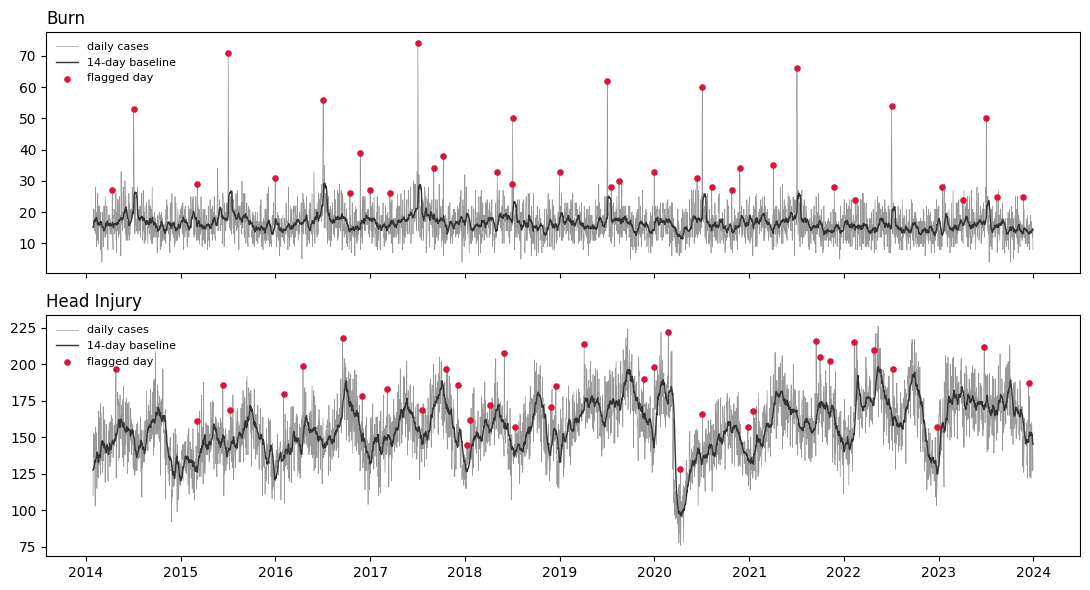

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, d in zip(axes, ["burn", "head_injury"]):
    res = results[(d, "case_sum")]
    ax.plot(res.index, res["value"], lw=0.5, color="0.6", label="daily cases")
    ax.plot(res.index, res["moving_avg"], lw=1, color="0.2", label=f"{WINDOW}-day baseline")
    ax.scatter(res.index[res["flag"]], res["value"][res["flag"]], color="crimson", s=14,
               label="flagged day", zorder=3)
    ax.set_title(d.replace("_", " ").title(), loc="left")
    ax.legend(loc="upper left", frameon=False, fontsize=8)
fig.tight_layout()

## The line list: is it worth pulling case files?

A flag is only a question. The line list puts the day's cases in front of the analyst, who decides whether the pattern is compelling enough to pick up the phone and pull the case files. Below: the strongest flag for each definition.

In [5]:
formats = pd.read_csv(demo / "neiss_formats.csv", dtype=str)
top = {d: results[(d, "case_sum")]["z"].idxmax() for d in ["burn", "head_injury"]}
if FULL:
    records = code_cases(read_records(raw, top.values()))
else:
    records = pd.read_csv(demo / "neiss_linelist_records.csv", parse_dates=["trmt_date"])
cols = ["trmt_date", "age_years", "sex", "bdpt", "diag", "disp", "prod1", "narrative"]

def line_list(d):
    cases = records[(records[d] == 1) & (records["trmt_date"] == top[d])]
    print(f"{d}: {top[d].date()}, {len(cases)} cases")
    return label(cases[cols], formats).round({"age_years": 1})

In [6]:
burns = line_list("burn")
print(burns["prod1"].value_counts().head(5).to_string())
burns.head(15)

burn: 2015-07-04, 71 cases
prod1
1313 - FIREWORKS                                        40
1934 - HOT WATER                                         8
3249 - GRILLS, NOT SPECIFIED                             4
264 - MICROWAVE OVENS                                    2
1682 - HAIR CURLERS, CURLING IRONS, CLIPS & HAIRPINS     2


,trmt_date,age_years,sex,bdpt,diag,disp,prod1,narrative
9,2015-07-04,7.0,FEMALE,82 - HAND,"51 - BURNS, THERMAL",1 - TREATED/EXAMINED AND RELEASED,1313 - FIREWORKS,7YOF WAS GOLDING A ROMAN CANDLE AND SUSTAINED ...
33,2015-07-04,2.0,MALE,76 - FACE,"51 - BURNS, THERMAL",1 - TREATED/EXAMINED AND RELEASED,1313 - FIREWORKS,2YOM SUSTAINED A THERMAL BURN TO FACE FROM A S...
52,2015-07-04,5.0,FEMALE,33 - LOWER ARM,"48 - BURN, SCALD",1 - TREATED/EXAMINED AND RELEASED,264 - MICROWAVE OVENS,5YOF GETTING HOT BUTTER OUT OF THE MICROWAVE O...
60,2015-07-04,44.0,MALE,77 - EYEBALL,"49 - BURN, CHEMICAL",1 - TREATED/EXAMINED AND RELEASED,954 - GENERAL PURPOSE HOUSEHOLD CLEANERS,44YOM CLEANING AT HOME AND GOT CLEANING SOLUTI...
78,2015-07-04,9.0,FEMALE,36 - LOWER LEG,"48 - BURN, SCALD",1 - TREATED/EXAMINED AND RELEASED,1934 - HOT WATER,9 YO FEMALE SPILLED HOT WATER ON LEG. DX BURN
83,2015-07-04,10.0,FEMALE,82 - HAND,"51 - BURNS, THERMAL",1 - TREATED/EXAMINED AND RELEASED,277 - CLOTHING IRONS,10 YO FEMALE TOUCHED A HOT IRON. DX BURN HAND
104,2015-07-04,15.0,FEMALE,82 - HAND,"51 - BURNS, THERMAL",1 - TREATED/EXAMINED AND RELEASED,1313 - FIREWORKS,15 YO FEMALE TRIED TO LIGHT 20 SPARKLERS AT ON...
119,2015-07-04,20.0,FEMALE,82 - HAND,"51 - BURNS, THERMAL",1 - TREATED/EXAMINED AND RELEASED,1313 - FIREWORKS,"DX DEEP PARTIAL THICKNESS BURNS TO L HAND, L 3..."
156,2015-07-04,68.0,FEMALE,36 - LOWER LEG,"48 - BURN, SCALD",1 - TREATED/EXAMINED AND RELEASED,"466 - COOKWARE, NOT SPECIFIED",68YR OLD FEMALE MOVING HOT PAN AND OIL SPLASHE...
162,2015-07-04,47.0,MALE,76 - FACE,"51 - BURNS, THERMAL",4 - TREATED AND ADMITTED/HOSPITALIZED,3248 - GAS OR LP GRILLS OR STOVES (FOR OUTDOOR...,"47 YR OLD MALE USING GRILL,PUSHED IGNITION AND..."


**Pull case files: no.** July 4, 2015: 71 burns, 40 of them from fireworks, most treated and released. The signal is real but expected; the response is prevention before the next Fourth of July, not case follow-up.

In [7]:
heads = line_list("head_injury")
print(heads["prod1"].value_counts().head(5).to_string())
heads.head(15)

head_injury: 2019-04-06, 214 cases
prod1
1807 - FLOORS OR FLOORING MATERIALS                                    27
4076 - BEDS OR BEDFRAMES, OTHER OR NOT SPECIFIED                       21
4057 - TABLES (EXCL.  BABY CHANGING TABLES, BILLIARD OR POOL TABLES    12
1842 - STAIRS OR STEPS                                                 11
1884 - CEILINGS AND WALLS (INTERIOR PART OF COMPLETED STRUCTURE)       10


,trmt_date,age_years,sex,bdpt,diag,disp,prod1,narrative
1069,2019-04-06,75.0,FEMALE,75 - HEAD,62 - INTERNAL INJURY,4 - TREATED AND ADMITTED/HOSPITALIZED,"4057 - TABLES (EXCL. BABY CHANGING TABLES, BI...","75YOF FELL ONTO NIGHTSTAND THEN BED, DX: CLSD ..."
1076,2019-04-06,64.0,MALE,75 - HEAD,52 - CONCUSSION,1 - TREATED/EXAMINED AND RELEASED,"4078 - LADDERS, OTHER OR NOT SPECIFIED","64YOM FELL 6-8' OFF NS LADDER, DX: CONCUSSION ..."
1084,2019-04-06,6.0,MALE,75 - HEAD,59 - LACERATION,1 - TREATED/EXAMINED AND RELEASED,"3273 - PLAYGROUND EQUIPMENT, NOT SPECIFIED","6YOM FELL ON NS PLAYGROUND EQUIPMENT, DX: LAC ..."
1089,2019-04-06,3.0,FEMALE,75 - HEAD,59 - LACERATION,1 - TREATED/EXAMINED AND RELEASED,"4057 - TABLES (EXCL. BABY CHANGING TABLES, BI...","3YOF FELL ON CORNER OF TABLE, DX: LAC SCALP"
1095,2019-04-06,0.2,MALE,75 - HEAD,62 - INTERNAL INJURY,1 - TREATED/EXAMINED AND RELEASED,"676 - RUGS OR CARPETS, NOT SPECIFIED",3MOM BEING HELD BY MOM WHEN MOM HAD SYNC & BOT...
1096,2019-04-06,0.1,MALE,75 - HEAD,62 - INTERNAL INJURY,1 - TREATED/EXAMINED AND RELEASED,1807 - FLOORS OR FLOORING MATERIALS,"1MOM ACCIDENTALLY DROPPED BY SIB ONTO FLOOR, D..."
1101,2019-04-06,73.0,MALE,75 - HEAD,62 - INTERNAL INJURY,1 - TREATED/EXAMINED AND RELEASED,"4078 - LADDERS, OTHER OR NOT SPECIFIED","73YOM FELL OFF NS LADDER, DX: CLSD HD INJ"
1104,2019-04-06,52.0,FEMALE,75 - HEAD,52 - CONCUSSION,1 - TREATED/EXAMINED AND RELEASED,1842 - STAIRS OR STEPS,"52YOF FELL DOWN 18 STEPS TO CONCRETE FLOOR, DX..."
1109,2019-04-06,77.0,FEMALE,75 - HEAD,62 - INTERNAL INJURY,4 - TREATED AND ADMITTED/HOSPITALIZED,1807 - FLOORS OR FLOORING MATERIALS,77YOF WAS WALKING DOWN THE HALLWAY AND BECAME...
1128,2019-04-06,58.0,FEMALE,75 - HEAD,62 - INTERNAL INJURY,1 - TREATED/EXAMINED AND RELEASED,1807 - FLOORS OR FLOORING MATERIALS,58YF TRIPPED&FELL BACKWARD WHILE AMBULATING WI...


**Pull case files: no.** April 6, 2019: 214 head injuries, spread across floors, beds, tables and stairs with no product or setting in common. It looks like a heavy day of ordinary falls; watch the following days rather than pull files.

## Where else it works

The same baseline-and-residual method runs on any daily count: emergency department syndromes, poison center calls, 311 complaints, crime reports. Only the case definition and the threshold change. The next notebook runs it unchanged on ten years of Chicago crime reports.

## Going further

- Change `WINDOW` or the thresholds in `python/utils/settings.py` and watch the flag rate move.
- Compare the count and ratio measures: which flags appear in one but not the other, and why?
- Look at every July 4 in the line lists: is the fireworks signal growing or shrinking?